# Практична робота №12
## Довірчі інтервали для середнього і частки

**Студент:** Панасюк Дмитро  
**Номер за списком групи:** 15  
**Варіант:** №5 — **Дніпро**  
**Вихідні дані:** липнева середньомісячна температура — **23 °C**.

**Мета:** згенерувати відтворювану вибірку денних температур, побудувати довірчий інтервал для середнього за *t*-розподілом та інтервал для частки за нормальним наближенням, порівняти ширину інтервалів для 90%, 95% і 99% довіри та коректно інтерпретувати їх.

*Зауваження:* усі 30 температур — синтетичні навчальні спостереження, а не фактичні метеовимірювання.

## Підготовка середовища
Імпортуємо NumPy, pandas та `scipy.stats` і задаємо параметри власного варіанта.

In [1]:
import numpy as np
import pandas as pd
from scipy import stats

variant = 5
city = "Дніпро"
july_temp = 23.0  # °C — дані варіанта №5
np.random.seed(variant)

print(f"Місто: {city}; варіант: №{variant}; липнева температура: {july_temp:.1f} °C")

Місто: Дніпро; варіант: №5; липнева температура: 23.0 °C


## Завдання 1. Вибірка денних температур
Генеруємо **30** випадкових денних температур навколо липневої середньомісячної температури за умовою: нормальний розподіл із центром 23 °C та стандартним відхиленням 2,5 °C. Використовуємо `np.random.seed(5)`, щоб кожен запуск давав однакові числа.

In [2]:
daily_temps = np.random.normal(loc=july_temp, scale=2.5, size=30)

n = len(daily_temps)
mean = daily_temps.mean()
s = daily_temps.std(ddof=1)

print("Згенеровані денні температури (°C):")
print(np.array2string(daily_temps, precision=2, separator=", "))
print(f"\nКількість спостережень: {n}")
print(f"Середнє: {mean:.4f} °C")
print(f"Вибіркове стандартне відхилення (ddof=1): {s:.4f} °C")
print(f"Відхилення вибіркового середнього від 23 °C: {abs(mean - july_temp):.4f} °C")

Згенеровані денні температури (°C):
[24.1 , 22.17, 29.08, 22.37, 23.27, 26.96, 20.73, 21.52, 23.47, 22.18,
 20.02, 22.49, 22.1 , 24.51, 18.84, 21.25, 25.88, 27.64, 19.22, 24.61,
 20.55, 20.86, 20.82, 21.94, 25.49, 24.78, 23.15, 22.09, 23.01, 22.74]

Кількість спостережень: 30
Середнє: 22.9277 °C
Вибіркове стандартне відхилення (ddof=1): 2.4151 °C
Відхилення вибіркового середнього від 23 °C: 0.0723 °C


**Висновок до завдання 1.** Вибіркове середнє становить **22,9277 °C** і близьке до табличних **23 °C**, але не дорівнює йому точно через випадкові відхилення. Вибіркове стандартне відхилення (з поправкою Бесселя, `ddof=1`) дорівнює **2,4151 °C**.

## Завдання 2. 95% довірчий інтервал для середньої температури

Оскільки справжнє стандартне відхилення генеральної сукупності $\sigma$ невідоме, використовуємо вибіркове $s$ та **t-розподіл Стьюдента** з $n-1=29$ ступенями свободи:

$$SE = \frac{s}{\sqrt{n}}, \qquad CI_{95\%} = \bar{x} \pm t_{0.975,\,n-1} \cdot SE.$$

`t.interval` обчислює обидві межі інтервалу.

In [3]:
se = s / np.sqrt(n)
t_critical = stats.t.ppf(0.975, df=n - 1)
ci_mean_95 = stats.t.interval(0.95, df=n - 1, loc=mean, scale=se)

print(f"Стандартна похибка середнього: {se:.6f} °C")
print(f"Ступені свободи: {n - 1}")
print(f"t-критичне для 95%: {t_critical:.5f}")
print(f"95% довірчий інтервал: [{ci_mean_95[0]:.4f}; {ci_mean_95[1]:.4f}] °C")

# Перевірка: інтервал, обчислений вручну, збігається зі scipy.stats
ci_mean_manual = (mean - t_critical * se, mean + t_critical * se)
assert np.allclose(ci_mean_95, ci_mean_manual)
print("Перевірка ручної формули проти stats.t.interval(): збіг підтверджено.")

Стандартна похибка середнього: 0.440938 °C
Ступені свободи: 29
t-критичне для 95%: 2.04523
95% довірчий інтервал: [22.0259; 23.8295] °C
Перевірка ручної формули проти stats.t.interval(): збіг підтверджено.


**Письмове пояснення.** Для побудови інтервалу ми оцінили невідоме генеральне стандартне відхилення за тією ж вибіркою (`s`), тому треба врахувати додаткову невизначеність. При **n = 30** правильний вибір за умовою — t-критичне значення, а не z-критичне для точно відомого σ. Нормальне z-наближення при 30 спостереженнях іноді використовують, але t-інтервал тут методологічно обґрунтованіший та трохи ширший.

**Результат:** 95% t-інтервал для середньої денної температури: **[22,0259; 23,8295] °C**.

## Завдання 3. 95% довірчий інтервал для частки

«Успіхом» вважаємо день, коли температура **строго вища** за табличне липневе значення **23 °C**.

Оцінка частки: $\hat{p} = k/n$. Перевіряємо умови нормального наближення $n\hat p\ge 5$ та $n(1-\hat p)\ge 5$; далі будуємо інтервал на основі нормальної апроксимації (Wald):

$$SE_{\hat p} = \sqrt{\frac{\hat p(1-\hat p)}{n}}, \qquad CI_{95\%} = \hat{p} \pm z_{0.975}\cdot SE_{\hat p}.$$


In [4]:
above_july = daily_temps > july_temp
k = int(above_july.sum())
p_hat = above_july.mean()
n_p, n_1p = n * p_hat, n * (1 - p_hat)
conditions_ok = n_p >= 5 and n_1p >= 5

se_p = np.sqrt(p_hat * (1 - p_hat) / n)
ci_prop_95 = stats.norm.interval(0.95, loc=p_hat, scale=se_p)

print(f"Днів вище {july_temp:.0f} °C: {k} із {n}")
print(f"Вибіркова частка p̂ = {p_hat:.6f} ({p_hat * 100:.2f}%)")
print(f"n · p̂ = {n_p:.0f}; n · (1 - p̂) = {n_1p:.0f}")
print(f"Умову обидва ≥ 5 виконано: {conditions_ok}")
print(f"Стандартна похибка частки: {se_p:.6f}")
print(f"95% інтервал частки: [{ci_prop_95[0]:.4f}; {ci_prop_95[1]:.4f}]")
print(f"Теоретична частка 0.5 входить до інтервалу: {ci_prop_95[0] <= 0.5 <= ci_prop_95[1]}")

assert conditions_ok, "Нормальне наближення не відповідає критерію завдання"
assert 0 <= ci_prop_95[0] <= ci_prop_95[1] <= 1

Днів вище 23 °C: 13 із 30
Вибіркова частка p̂ = 0.433333 (43.33%)
n · p̂ = 13; n · (1 - p̂) = 17
Умову обидва ≥ 5 виконано: True
Стандартна похибка частки: 0.090472
95% інтервал частки: [0.2560; 0.6107]
Теоретична частка 0.5 входить до інтервалу: True


**Письмова перевірка.** Понад 23 °C виявилося **13 із 30 днів**, тобто **43,33%**. Для нормального наближення маємо **13 успіхів** і **17 неуспіхів**; обидва числа не менші 5, тому за критерієм із завдання застосування формули прийнятне.

**Результат:** 95% інтервал для частки — **[0,2560; 0,6107]**, або приблизно **від 25,60% до 61,07%**. Теоретична частка **0,5** потрапляє в інтервал. Це узгоджується із симетричною нормальною моделлю, за якою половина денних температур теоретично вища за 23 °C. Нормальне наближення для частки є наближеним, навіть коли умова кількості успіхів/неуспіхів виконується.

## Завдання 4. Зміна ширини інтервалу за рівнем довіри
За тією самою вибіркою обчислюємо t-інтервали для **90%, 95% і 99%** довіри. Для кожного визначаємо ширину `верхня − нижня`.

In [5]:
conf_levels = [0.90, 0.95, 0.99]
interval_rows = []

for level in conf_levels:
    lower, upper = stats.t.interval(level, df=n - 1, loc=mean, scale=se)
    interval_rows.append({
        "Рівень довіри": f"{level:.0%}",
        "Нижня межа, °C": lower,
        "Верхня межа, °C": upper,
        "Ширина, °C": upper - lower,
    })

interval_table = pd.DataFrame(interval_rows)
print(interval_table.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
assert interval_table["Ширина, °C"].is_monotonic_increasing

Рівень довіри  Нижня межа, °C  Верхня межа, °C  Ширина, °C
          90%         22.1785          23.6769      1.4984
          95%         22.0259          23.8295      1.8036
          99%         21.7123          24.1431      2.4308


**Письмовий висновок.** Ширина зростає зі збільшенням рівня довіри: **1,4984 °C** (90%) → **1,8036 °C** (95%) → **2,4308 °C** (99%). Причина: більша частка інтервалів має охоплювати справжній параметр, тож потрібне більше критичне t-значення та ширші межі.

Щоб отримати **вужчий 99% інтервал** без зниження рівня довіри, передусім треба **збільшити розмір вибірки n**, тобто витратити ресурси на додаткові спостереження. За інших рівних умов `SE = s / √n` при цьому зменшується.

### Додаткова візуалізація довірчих інтервалів
Графік показує, як із підвищенням рівня довіри розширюється оцінений діапазон середньої температури.

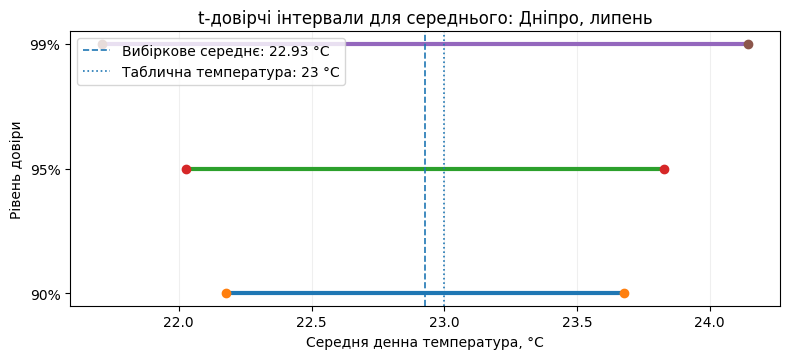

In [6]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 3.7))
for i, record in enumerate(interval_rows):
    ax.plot([record["Нижня межа, °C"], record["Верхня межа, °C"]], [i, i], linewidth=3)
    ax.plot([record["Нижня межа, °C"], record["Верхня межа, °C"]], [i, i], "o", markersize=6)

ax.axvline(mean, linestyle="--", linewidth=1.2, label=f"Вибіркове середнє: {mean:.2f} °C")
ax.axvline(july_temp, linestyle=":", linewidth=1.2, label=f"Таблична температура: {july_temp:.0f} °C")
ax.set_yticks(range(len(interval_rows)), [r["Рівень довіри"] for r in interval_rows])
ax.set_xlabel("Середня денна температура, °C")
ax.set_ylabel("Рівень довіри")
ax.set_title("t-довірчі інтервали для середнього: Дніпро, липень")
ax.grid(axis="x", alpha=0.2)
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

## Завдання 5. Правильна інтерпретація 95% довірчого інтервалу

Побудована процедура дала інтервал **від 22,0259 °C до 23,8295 °C** як оцінку середньої денної температури для використаної моделі. Якби ми багаторазово отримували **незалежні вибірки по 30 днів** за однакових умов і щоразу будували такий самий t-інтервал, то в довгій серії **приблизно 95% побудованих інтервалів** охоплювали б справжнє середнє генеральної сукупності. Серед 100 повторень можна очікувати близько 95 таких інтервалів, але точна кількість не гарантована. Для конкретного вже обчисленого інтервалу справжнє середнє або входить до нього, або ні; **95% характеризують надійність методу, а не ймовірність перебування фіксованого параметра у вже отриманих межах**.

## Контрольні питання

**1. Чим точкова оцінка відрізняється від довірчого інтервалу?**  
Точкова оцінка (`mean = 22,9277 °C`) — це одне число, отримане з вибірки як оцінка невідомого середнього. Через випадковий характер вибірки це число може відхилятися від істинного параметра. Довірчий інтервал додає інформацію про **невизначеність оцінки**, задаючи діапазон, побудований методом із визначеною довгостроковою частотою охоплення параметра.

**2. Чому при невідомому σ та n = 30 використовують t-розподіл?**  
Справжнє генеральне відхилення σ не задано: замінюємо його вибірковим `s`, оціненим з тих самих 30 значень. t-розподіл із `n − 1 = 29` ступенями свободи враховує додаткову невизначеність цієї заміни; його критичні значення для того самого рівня довіри більші за z-критичні. За нормальності вихідної сукупності t-інтервал є коректним способом побудови інтервалу для середнього.

**3. Що означає 95% довіри? Чому вислів «95% імовірності, що параметр у цьому конкретному інтервалі» некоректний?**  
Якщо багато разів повторювати процедуру вибірки та обчислення інтервалу за тим самим правилом, **близько 95% цих випадкових інтервалів** накриватимуть фіксоване справжнє середнє. Після спостереження даних обидві межі конкретного інтервалу вже визначено, а параметр в частотному підході не є випадковою величиною: він або всередині, або поза інтервалом. Число 95% стосується **процедури отримання інтервалів**.

**4. Які три фактори визначають ширину довірчого інтервалу?**  
**Рівень довіри:** вищий рівень вимагає більшого критичного значення — інтервал **ширший**. **Розкид даних (s):** більше стандартне відхилення збільшує стандартну похибку — інтервал **ширший**. **Розмір вибірки (n):** зі збільшенням n стандартна похибка приблизно спадає як `1/√n` — інтервал **вужчий** (для t-інтервалу змінюється також число ступенів свободи).

## Підсумок

- Згенеровано **30** навчальних денних температур для **Дніпра** з фіксованим `seed=5`.
- Обчислено `mean = 22,9277 °C`, `s = 2,4151 °C`, побудовано **95% t-інтервал [22,0259; 23,8295] °C**.
- Для днів із температурою **понад 23 °C** знайдено `p̂ = 13/30 = 0,4333`, перевірено умову нормального наближення й побудовано **95% інтервал частки [0,2560; 0,6107]**.
- Порівняно інтервали **90%, 95%, 99%**; наведено правильну частотну інтерпретацію 95% довіри та письмові відповіді на всі контрольні запитання.